# Data Profiling Spotify & Grammy Awards

Objetivo: recolectar evidencia sobre la estructura y calidad de ambas fuentes para fundamentar los requerimientos analíticos, los riesgos de calidad y las reglas de validación.


Fuentes:
- `data/raw/spotify_dataset.csv`
- `data/raw/the_grammy_awards.csv` (perfilado desde el CSV; se reconciliará con la tabla fuente en PostgreSQL)

In [2]:
import sys
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def encontrar_raiz(inicio: Path) -> Path:
    """Busca hacia arriba la carpeta del proyecto (la que contiene data/raw)."""
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "raw").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró data/raw en ningún directorio superior")


RAIZ = encontrar_raiz(Path.cwd())
RUTA_SPOTIFY = RAIZ / "data" / "raw" / "spotify_dataset.csv"
RUTA_GRAMMY = RAIZ / "data" / "raw" / "the_grammy_awards.csv"

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Raíz del proyecto:", RAIZ)

Python: 3.12.15
pandas: 2.3.3 | numpy: 2.5.4 | matplotlib: 3.11.2
Raíz del proyecto: /Users/santiago/Desktop/Workshop-2


## 1. Estructura
Integridad de los archivos, dimensiones, tipos inferidos y perfil por columna.

In [3]:
def sha256(ruta: Path) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


lineas_fisicas = {}
for ruta in [RUTA_SPOTIFY, RUTA_GRAMMY]:
    with open(ruta, "r", encoding="utf-8") as f:
        encabezado = f.readline().rstrip("\n")
        lineas_fisicas[ruta.name] = 1 + sum(1 for _ in f)
    print(ruta.name)
    print(f"  tamaño: {ruta.stat().st_size / 1_048_576:.2f} MB")
    print(f"  sha256: {sha256(ruta)}")
    print(f"  líneas físicas (incluye encabezado): {lineas_fisicas[ruta.name]:,}")
    print(f"  encabezado: {encabezado[:250]}")

spotify_dataset.csv
  tamaño: 19.19 MB
  sha256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
  líneas físicas (incluye encabezado): 114,001
  encabezado: ,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
the_grammy_awards.csv
  tamaño: 1.40 MB
  sha256: bae3d6613cb39adb597bb8864fb294144bd55cb452557536f324020266727d88
  líneas físicas (incluye encabezado): 4,811
  encabezado: year,title,published_at,updated_at,category,nominee,artist,workers,img,winner


In [4]:
# Lectura 1: comportamiento por defecto de pandas (inferencia de tipos y tokens nulos estándar)
spotify = pd.read_csv(RUTA_SPOTIFY)
grammy = pd.read_csv(RUTA_GRAMMY)

# Lectura 2: todo como texto, sin convertir ningún token a nulo (valores tal como vienen en el archivo)
spotify_txt = pd.read_csv(RUTA_SPOTIFY, dtype=str, keep_default_na=False)
grammy_txt = pd.read_csv(RUTA_GRAMMY, dtype=str, keep_default_na=False)

for nombre, df, archivo in [("spotify", spotify, RUTA_SPOTIFY.name), ("grammy", grammy, RUTA_GRAMMY.name)]:
    print(f"{nombre}: {df.shape[0]:,} filas x {df.shape[1]} columnas | "
          f"memoria {df.memory_usage(deep=True).sum() / 1_048_576:.1f} MB | "
          f"líneas de datos en el archivo: {lineas_fisicas[archivo] - 1:,}")

spotify: 114,000 filas x 21 columnas | memoria 49.7 MB | líneas de datos en el archivo: 114,000
grammy: 4,810 filas x 10 columnas | memoria 3.1 MB | líneas de datos en el archivo: 4,810


In [5]:
def perfil_columnas(df: pd.DataFrame) -> pd.DataFrame:
    n = len(df)
    filas = []
    for col in df.columns:
        s = df[col]
        filas.append({
            "columna": col,
            "dtype": str(s.dtype),
            "no_nulos": int(s.notna().sum()),
            "nulos": int(s.isna().sum()),
            "pct_nulos": round(s.isna().mean() * 100, 3),
            "distintos": int(s.nunique(dropna=True)),
            "pct_distintos": round(s.nunique(dropna=True) / n * 100, 3),
            "ejemplos": list(s.dropna().unique()[:3]),
        })
    return pd.DataFrame(filas).set_index("columna")


print("=== SPOTIFY ===")
print(perfil_columnas(spotify).to_string(max_colwidth=50))
print("\n=== GRAMMY ===")
print(perfil_columnas(grammy).to_string(max_colwidth=50))

=== SPOTIFY ===
                    dtype  no_nulos  nulos  pct_nulos  distintos  pct_distintos                                           ejemplos
columna                                                                                                                           
Unnamed: 0          int64    114000      0      0.000     114000        100.000                                          [0, 1, 2]
track_id           object    114000      0      0.000      89741         78.720  [5SuOikwiRyPMVoIQDJUgSV, 4qPNDBW1i3p13qLCt0Ki3...
artists            object    113999      1      0.001      31437         27.576  [Gen Hoshino, Ben Woodward, Ingrid Michaelson;...
album_name         object    113999      1      0.001      46589         40.868         [Comedy, Ghost (Acoustic), To Begin Again]
track_name         object    113999      1      0.001      73608         64.568         [Comedy, Ghost - Acoustic, To Begin Again]
popularity          int64    114000      0      0.000        101   

In [6]:
print("=== SPOTIFY (3 filas, transpuesto) ===")
print(spotify.head(3).T.to_string(max_colwidth=60))
print("\n=== GRAMMY (3 filas, transpuesto) ===")
print(grammy.head(3).T.to_string(max_colwidth=60))

=== SPOTIFY (3 filas, transpuesto) ===
                                       0                       1                       2
Unnamed: 0                             0                       1                       2
track_id          5SuOikwiRyPMVoIQDJUgSV  4qPNDBW1i3p13qLCt0Ki3A  1iJBSr7s7jYXzM8EGcbK5b
artists                      Gen Hoshino            Ben Woodward  Ingrid Michaelson;ZAYN
album_name                        Comedy        Ghost (Acoustic)          To Begin Again
track_name                        Comedy        Ghost - Acoustic          To Begin Again
popularity                            73                      55                      57
duration_ms                       230666                  149610                  210826
explicit                           False                   False                   False
danceability                       0.676                    0.42                   0.438
energy                             0.461                   0.166       

## 2. Completitud
Nulos detectados por pandas, nulos "disfrazados" en el texto crudo y patrones de nulidad.

In [7]:
TOKENS_NULOS_TEXTO = {"na", "n/a", "nan", "null", "none", "-", "?", "unknown", "desconocido"}


def revisar_texto_crudo(df_txt: pd.DataFrame) -> pd.DataFrame:
    filas = []
    for col in df_txt.columns:
        s = df_txt[col]
        rec = s.str.strip()
        es_token = rec.str.lower().isin(TOKENS_NULOS_TEXTO)
        filas.append({
            "columna": col,
            "vacios": int((s == "").sum()),
            "solo_espacios": int(((rec == "") & (s != "")).sum()),
            "tokens_sospechosos": int(es_token.sum()),
            "tokens_encontrados": sorted(rec[es_token].unique().tolist())[:5],
            "espacios_en_bordes": int(((s != rec) & (rec != "")).sum()),
        })
    out = pd.DataFrame(filas).set_index("columna")
    metricas = ["vacios", "solo_espacios", "tokens_sospechosos", "espacios_en_bordes"]
    return out[(out[metricas] > 0).any(axis=1)]


print("=== SPOTIFY: columnas con hallazgos en texto crudo ===")
print(revisar_texto_crudo(spotify_txt).to_string())
print("\n=== GRAMMY: columnas con hallazgos en texto crudo ===")
print(revisar_texto_crudo(grammy_txt).to_string())

=== SPOTIFY: columnas con hallazgos en texto crudo ===
            vacios  solo_espacios  tokens_sospechosos tokens_encontrados  espacios_en_bordes
columna                                                                                     
artists          1              0                   0                 []                   8
album_name       1              0                  21       [?, unknown]                   0
track_name       1              0                   0                 []                   0

=== GRAMMY: columnas con hallazgos en texto crudo ===
         vacios  solo_espacios  tokens_sospechosos tokens_encontrados  espacios_en_bordes
columna                                                                                  
nominee       6              0                   0                 []                   0
artist     1840              0                   0                 []                   0
workers    2190              0                   0               

In [8]:
filas_nulas_sp = spotify[spotify.isna().any(axis=1)]
print(f"SPOTIFY — filas con al menos un nulo: {len(filas_nulas_sp):,}")
print(filas_nulas_sp.head(10).to_string(max_colwidth=40))

cols_nulas_gr = grammy.columns[grammy.isna().any()].tolist()
print(f"\nGRAMMY — filas con al menos un nulo: {grammy.isna().any(axis=1).sum():,}")
print("Columnas con nulos:", cols_nulas_gr)
print("\nPatrones de nulidad (True = nulo) y su frecuencia:")
print(grammy[cols_nulas_gr].isna().value_counts().to_string())

SPOTIFY — filas con al menos un nulo: 1
       Unnamed: 0                track_id artists album_name track_name  popularity  duration_ms  explicit  danceability  energy  key  loudness  mode  speechiness  acousticness  instrumentalness  liveness  valence    tempo  time_signature track_genre
65900       65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN           0            0     False         0.501   0.583    7     -9.46     0       0.0605          0.69           0.00396    0.0747    0.734  138.391               4       k-pop

GRAMMY — filas con al menos un nulo: 3,976
Columnas con nulos: ['nominee', 'artist', 'workers', 'img']

Patrones de nulidad (True = nulo) y su frecuencia:
nominee  artist  workers  img  
False    False   True     False    1597
         True    False    False    1006
         False   False    False     834
         True    False    True      648
         False   True     True      407
         True    True     True      174
         False   False    True

## 3. Unicidad y duplicados
Duplicados completos, llaves candidatas y grano observado de cada fuente.

In [9]:
col_indice = spotify.columns[0]
print(f"Primera columna: '{col_indice}'")
print("¿Es igual a 0..n-1?:", bool((spotify[col_indice].to_numpy() == np.arange(len(spotify))).all()))

print("\nFilas duplicadas completas:", int(spotify.duplicated().sum()))
print("Filas duplicadas ignorando la primera columna:", int(spotify.drop(columns=[col_indice]).duplicated().sum()))

repetido = spotify["track_id"].duplicated(keep=False)
print(f"\ntrack_id distintos: {spotify['track_id'].nunique():,} de {len(spotify):,} filas")
print(f"Filas cuyo track_id se repite: {int(repetido.sum()):,}")
print(f"track_id que aparecen más de una vez: {spotify.loc[repetido, 'track_id'].nunique():,}")
print("\nDistribución (veces que aparece un track_id -> cuántos track_id):")
print(spotify["track_id"].value_counts().value_counts().sort_index().to_string())

print("\n¿Qué columnas cambian dentro de un mismo track_id repetido? (n.º de track_id donde varía)")
variacion = (spotify.loc[repetido].drop(columns=[col_indice])
             .groupby("track_id").nunique(dropna=False) > 1).sum()
print(variacion[variacion > 0].sort_values(ascending=False).to_string())

ids_por_cancion = spotify.groupby(["artists", "track_name"], dropna=False)["track_id"].nunique()
print(f"\nCombinaciones (artists, track_name): {len(ids_por_cancion):,}")
print(f"Combinaciones con más de un track_id: {int((ids_por_cancion > 1).sum()):,}")
print(ids_por_cancion.sort_values(ascending=False).head(10).to_string())

Primera columna: 'Unnamed: 0'
¿Es igual a 0..n-1?: True

Filas duplicadas completas: 0
Filas duplicadas ignorando la primera columna: 450

track_id distintos: 89,741 de 114,000 filas
Filas cuyo track_id se repite: 40,900
track_id que aparecen más de una vez: 16,641

Distribución (veces que aparece un track_id -> cuántos track_id):
count
1    73100
2    11712
3     2984
4     1372
5      431
6      117
7       22
8        2
9        1

¿Qué columnas cambian dentro de un mismo track_id repetido? (n.º de track_id donde varía)
track_genre    16299
popularity       720

Combinaciones (artists, track_name): 81,344
Combinaciones con más de un track_id: 4,657
artists          track_name                                 
Brenda Lee       Rockin' Around The Christmas Tree              45
The Beach Boys   Little Saint Nick - 1991 Remix                 41
Chuck Berry      Run Rudolph Run                                40
Ella Fitzgerald  Frosty The Snowman                             34
Dean Martin

In [10]:
print("Filas duplicadas completas:", int(grammy.duplicated().sum()))
for clave in [["year", "category", "nominee"], ["year", "category", "nominee", "artist"]]:
    n_rep = int(grammy.duplicated(subset=clave, keep=False).sum())
    print(f"Clave candidata {clave}: {n_rep} filas en grupos repetidos")

print("\nFilas por (year, category) — grano observado:")
print(grammy.groupby(["year", "category"]).size().describe().to_string())

Filas duplicadas completas: 0
Clave candidata ['year', 'category', 'nominee']: 0 filas en grupos repetidos
Clave candidata ['year', 'category', 'nominee', 'artist']: 0 filas en grupos repetidos

Filas por (year, category) — grano observado:
count    4430.000000
mean        1.085779
std         0.578731
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         8.000000


## 4. Contenido categórico
Dominios, frecuencias y variaciones de escritura (mayúsculas, espacios).

In [11]:
print("=== SPOTIFY ===")
print(f"track_genre distintos: {spotify['track_genre'].nunique()}")
print("Tamaño de los géneros (resumen de filas por género):")
print(spotify["track_genre"].value_counts().describe().to_string())
for col in ["explicit", "key", "mode", "time_signature"]:
    print(f"\n{col}:")
    print(spotify[col].value_counts(dropna=False).sort_index().to_string())
print(f"\nartists distintos (campo completo): {spotify['artists'].nunique():,}")
print(spotify["artists"].value_counts().head(10).to_string())

print("\n=== GRAMMY ===")
print(f"title distintos: {grammy['title'].nunique()}")
print(grammy["title"].value_counts().head(5).to_string())
print(f"\ncategory distintos: {grammy['category'].nunique()}")
print(grammy["category"].value_counts().head(15).to_string())
print("\nwinner:")
print(grammy["winner"].value_counts(dropna=False).to_string())
print(f"\nartist distintos: {grammy['artist'].nunique():,}")
print(grammy["artist"].value_counts().head(10).to_string())

=== SPOTIFY ===
track_genre distintos: 114
Tamaño de los géneros (resumen de filas por género):
count     114.0
mean     1000.0
std         0.0
min      1000.0
25%      1000.0
50%      1000.0
75%      1000.0
max      1000.0

explicit:
explicit
False    104253
True       9747

key:
key
0     13061
1     10772
2     11644
3      3570
4      9008
5      9368
6      7921
7     13245
8      7360
9     11313
10     7456
11     9282

mode:
mode
0    41319
1    72681

time_signature:
time_signature
0       163
1       973
3      9195
4    101843
5      1826

artists distintos (campo completo): 31,437
artists
The Beatles        279
George Jones       271
Stevie Wonder      236
Linkin Park        224
Ella Fitzgerald    222
Prateek Kuhad      217
Feid               202
Chuck Berry        190
Håkan Hellström    183
OneRepublic        181

=== GRAMMY ===
title distintos: 62
title
62nd Annual GRAMMY Awards  (2019)    433
50th Annual GRAMMY Awards  (2007)    111
51st Annual GRAMMY Awards  (2008)    1

In [12]:
def variantes_de_escritura(s: pd.Series, top: int = 8) -> None:
    s = s.dropna().astype(str)
    norm = s.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
    tabla = pd.DataFrame({"original": s, "normalizado": norm}).drop_duplicates()
    conteo = tabla.groupby("normalizado")["original"].nunique()
    con_variantes = conteo[conteo > 1]
    print(f"[{s.name}] distintos: {s.nunique():,} | tras normalizar: {norm.nunique():,} | "
          f"grupos con más de una escritura: {len(con_variantes):,}")
    if len(con_variantes):
        ejemplos = tabla[tabla["normalizado"].isin(con_variantes.index[:top])].sort_values("normalizado")
        print(ejemplos.to_string(index=False, max_colwidth=60))
    print()


for col in ["track_genre", "artists", "album_name", "track_name"]:
    variantes_de_escritura(spotify[col])
for col in ["category", "artist", "nominee"]:
    variantes_de_escritura(grammy[col])

[track_genre] distintos: 114 | tras normalizar: 114 | grupos con más de una escritura: 0

[artists] distintos: 31,437 | tras normalizar: 31,428 | grupos con más de una escritura: 9
                         original                       normalizado
                         Deadlife                          deadlife
                         DEADLIFE                          deadlife
                 Desejo De Menina                  desejo de menina
                 Desejo de Menina                  desejo de menina
                 DJ Fixx;Ondamike                  dj fixx;ondamike
                 DJ Fixx;OnDaMiKe                  dj fixx;ondamike
                           Fisher                            fisher
                           FISHER                            fisher
                             LiSA                              lisa
                             LISA                              lisa
                     Los Hermanos                      los hermanos
   

## 5. Contenido numérico
Rangos, percentiles, ceros, negativos y señales de valores atípicos (IQR x 1.5, solo como señal).

In [13]:
num_spotify = spotify.select_dtypes(include="number").drop(columns=[col_indice])

resumen = num_spotify.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
resumen["ceros"] = (num_spotify == 0).sum()
resumen["negativos"] = (num_spotify < 0).sum()
q1, q3 = num_spotify.quantile(0.25), num_spotify.quantile(0.75)
iqr = q3 - q1
resumen["atipicos_iqr"] = ((num_spotify < q1 - 1.5 * iqr) | (num_spotify > q3 + 1.5 * iqr)).sum()
print(resumen.round(4).to_string())

                     count         mean          std     min          1%          25%          50%          75%         99%          max  ceros  negativos  atipicos_iqr
popularity        114000.0      33.2385      22.3051   0.000      0.0000      17.0000      35.0000      50.0000      80.000      100.000  16020          0             2
duration_ms       114000.0  228029.1531  107297.7126   0.000  64652.9000  174066.0000  212906.0000  261506.0000  530907.660  5237295.000      1          0          5617
danceability      114000.0       0.5668       0.1735   0.000      0.1340       0.4560       0.5800       0.6950       0.901        0.985    157          0           620
energy            114000.0       0.6414       0.2515   0.000      0.0309       0.4720       0.6850       0.8540       0.993        1.000      1          0             0
key               114000.0       5.3091       3.5600   0.000      0.0000       2.0000       5.0000       8.0000      11.000       11.000  13061          0 

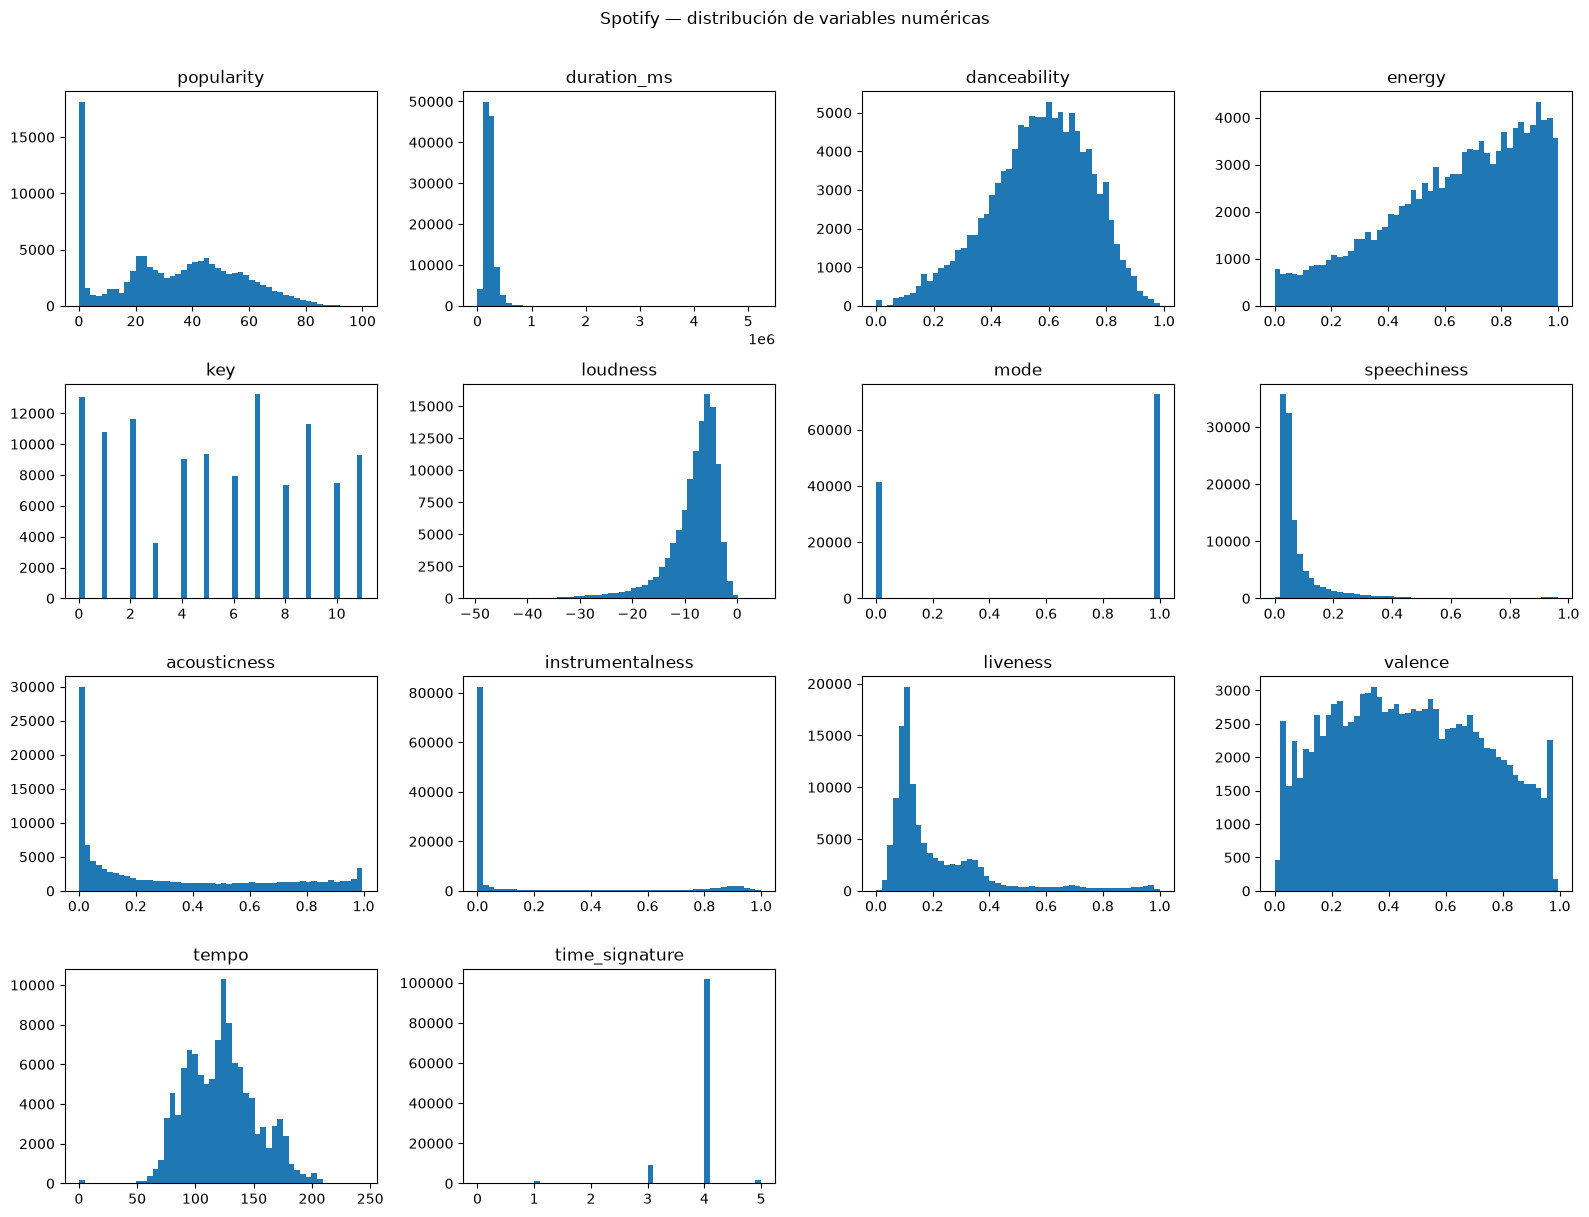

In [14]:
cols = num_spotify.columns
n_filas = int(np.ceil(len(cols) / 4))
fig, axes = plt.subplots(n_filas, 4, figsize=(16, 3 * n_filas))
for ax, col in zip(axes.flat, cols):
    ax.hist(num_spotify[col].dropna(), bins=50)
    ax.set_title(col)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.suptitle("Spotify — distribución de variables numéricas", y=1.01)
plt.tight_layout()
plt.show()

## 6. Contenido temporal
Spotify no trae columnas de fecha (se verifica). En Grammy: cobertura de años, huecos, fechas parseables y coherencia entre `year` y el año que aparece en `title`.

In [15]:
print("SPOTIFY — columnas de tipo fecha o con 'date'/'year' en el nombre:",
      [c for c in spotify.columns if "date" in c.lower() or "year" in c.lower()] or "ninguna")

print(f"\nGRAMMY — year: min {grammy['year'].min()} | max {grammy['year'].max()} | distintos {grammy['year'].nunique()}")
rango = set(range(grammy["year"].min(), grammy["year"].max() + 1))
print("Años sin registros dentro del rango:", sorted(rango - set(grammy["year"].unique())) or "ninguno")

for col in ["published_at", "updated_at"]:
    parseado = pd.to_datetime(grammy[col], errors="coerce", utc=True)
    no_parse = int((parseado.isna() & grammy[col].notna()).sum())
    print(f"\n{col}: distintos {grammy[col].nunique()} | no parseables {no_parse} | "
          f"min {parseado.min()} | max {parseado.max()}")
    print(grammy[col].value_counts().head(5).to_string())

anio_titulo = pd.to_numeric(grammy["title"].str.extract(r"\((\d{4})\)")[0], errors="coerce")
print(f"\ntitle con año entre paréntesis: {int(anio_titulo.notna().sum()):,} de {len(grammy):,}")
print("Diferencia year - año_en_title (frecuencia):")
print((grammy["year"] - anio_titulo).value_counts(dropna=False).to_string())

SPOTIFY — columnas de tipo fecha o con 'date'/'year' en el nombre: ninguna

GRAMMY — year: min 1958 | max 2019 | distintos 62
Años sin registros dentro del rango: ninguno

published_at: distintos 4 | no parseables 0 | min 2017-11-28 08:03:45+00:00 | max 2020-05-19 12:10:28+00:00
published_at
2017-11-28T00:03:45-08:00    4205
2020-05-19T05:10:28-07:00     433
2018-12-06T23:48:49-08:00      86
2018-05-22T03:08:24-07:00      86

updated_at: distintos 10 | no parseables 0 | min 2017-11-28 08:03:45+00:00 | max 2020-09-01 19:16:40+00:00
updated_at
2019-09-10T01:08:19-07:00    778
2019-09-10T01:06:11-07:00    754
2019-09-10T01:07:37-07:00    713
2019-09-10T01:06:59-07:00    681
2019-09-10T01:11:09-07:00    658

title con año entre paréntesis: 4,810 de 4,810
Diferencia year - año_en_title (frecuencia):
0    4810


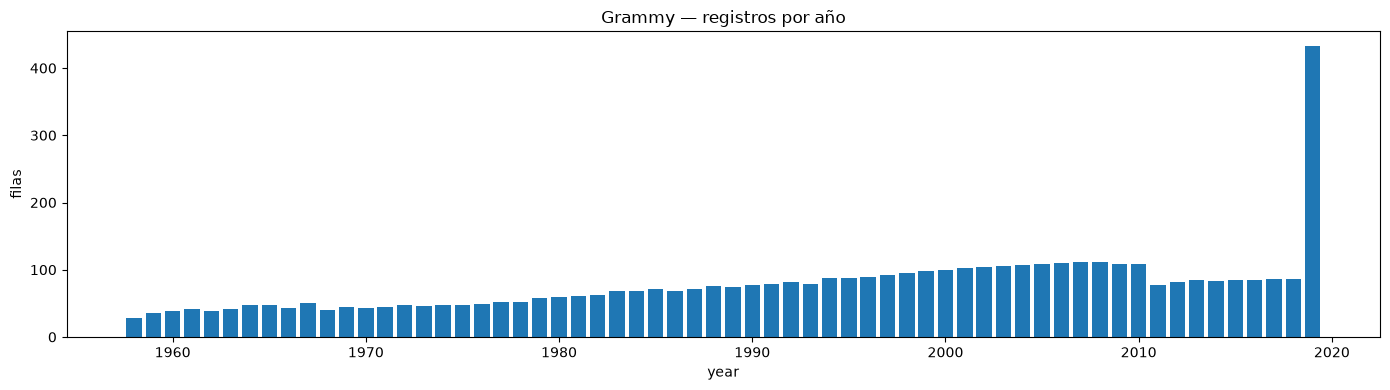

In [16]:
conteo_anual = grammy["year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(conteo_anual.index, conteo_anual.values)
ax.set_title("Grammy — registros por año")
ax.set_xlabel("year")
ax.set_ylabel("filas")
plt.tight_layout()
plt.show()

## 7. Consistencia entre fuentes
Primera medición de compatibilidad para integrar: el artista en ambas fuentes. La normalización aplicada es mínima y solo sirve para medir.

In [17]:
def norm_basica(s: pd.Series) -> pd.Series:
    return s.astype(str).str.strip().str.lower().str.replace(r"\s+", " ", regex=True)


patrones = {
    "';'": r";",
    "' & '": r" & ",
    "','": r",",
    "'and'": r"\band\b",
    "'feat./featuring'": r"\bfeat(?:uring|\.)",
    "'with'": r"\bwith\b",
}
print("Filas que contienen cada separador:")
for nombre, pat in patrones.items():
    n_sp = int(spotify["artists"].str.contains(pat, case=False, regex=True, na=False).sum())
    n_gr = int(grammy["artist"].str.contains(pat, case=False, regex=True, na=False).sum())
    print(f"  {nombre:<20} spotify.artists: {n_sp:>7,} | grammy.artist: {n_gr:>5,}")

sp_campo = spotify["artists"].dropna()
gr_campo = grammy["artist"].dropna()
sp_campo_norm = set(norm_basica(sp_campo))
sp_individual_norm = set(norm_basica(sp_campo.str.split(";").explode()))
gr_norm = set(norm_basica(gr_campo))

print(f"\nArtistas distintos en Grammy (no nulos): {gr_campo.nunique():,}")
print(f"  coincidencia exacta con el campo completo de Spotify: {len(set(gr_campo.unique()) & set(sp_campo.unique())):,}")
print(f"  coincidencia normalizada con el campo completo:        {len(gr_norm & sp_campo_norm):,}")
print(f"  coincidencia normalizada con artistas individuales (split ';'): {len(gr_norm & sp_individual_norm):,}")

no_encontrados = pd.Series(sorted(gr_norm - sp_individual_norm))
print(f"\nArtistas Grammy sin coincidencia: {len(no_encontrados):,}. Muestra aleatoria (semilla 42):")
print(no_encontrados.sample(min(20, len(no_encontrados)), random_state=42).to_string(index=False))

Filas que contienen cada separador:
  ';'                  spotify.artists:  30,075 | grammy.artist:     4
  ' & '                spotify.artists:   2,871 | grammy.artist:   411
  ','                  spotify.artists:     273 | grammy.artist:   124
  'and'                spotify.artists:     431 | grammy.artist:    61
  'feat./featuring'    spotify.artists:       1 | grammy.artist:    87
  'with'               spotify.artists:      83 | grammy.artist:    25

Artistas distintos en Grammy (no nulos): 1,658
  coincidencia exacta con el campo completo de Spotify: 404
  coincidencia normalizada con el campo completo:        408
  coincidencia normalizada con artistas individuales (split ';'): 524

Artistas Grammy sin coincidencia: 1,132. Muestra aleatoria (semilla 42):
                                       paula abdul
                                      sam and dave
                                   grover mitchell
james horner, barry mann & cynthia weil, songwr...
                     

# Segunda pasada de profiling

Investigaciones dirigidas por los requerimientos aprobados (R1–R4). Igual que en la primera pasada, este notebook mide y no modifica los datos fuente. La década se deriva de `year` tal como viene en el dataset.

In [18]:
import re
import unicodedata


def quitar_tildes(texto: str) -> str:
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))


def norm_fuerte(serie: pd.Series) -> pd.Series:
    """Clave de comparación: minúsculas, sin tildes, espacios colapsados. Solo para medir."""
    unicos = serie.dropna().astype(str).unique()
    mapa = {u: re.sub(r"\s+", " ", quitar_tildes(u).strip().lower()) for u in unicos}
    return serie.map(mapa)


g = grammy.copy()
g["decada"] = (g["year"] // 10) * 10
g["artist_nulo"] = g["artist"].isna()
print("Décadas en Grammy:", sorted(g["decada"].unique()))

Décadas en Grammy: [np.int64(1950), np.int64(1960), np.int64(1970), np.int64(1980), np.int64(1990), np.int64(2000), np.int64(2010)]


## 1. Grammy: 2019 y la reestructuración de 2011

In [19]:
por_anio = g.groupby("year").agg(filas=("category", "size"), categorias=("category", "nunique"))
por_anio["filas_por_categoria"] = (por_anio["filas"] / por_anio["categorias"]).round(2)
print(por_anio.loc[2007:2019].to_string())

print("\npublished_at -> años que cubre:")
print(g.groupby("published_at")["year"].agg(["min", "max", "count"]).to_string())

print("\nupdated_at -> años que cubre:")
print(g.groupby("updated_at")["year"].agg(["min", "max", "count"]).to_string())

      filas  categorias  filas_por_categoria
year                                        
2007    111         110                 1.01
2008    111         110                 1.01
2009    109         109                 1.00
2010    109         108                 1.01
2011     78          78                 1.00
2012     82          81                 1.01
2013     84          82                 1.02
2014     83          83                 1.00
2015     84          83                 1.01
2016     85          84                 1.01
2017     86          84                 1.02
2018     86          84                 1.02
2019    433          84                 5.15

published_at -> años que cubre:
                            min   max  count
published_at                                
2017-11-28T00:03:45-08:00  1958  2016   4205
2018-05-22T03:08:24-07:00  2017  2017     86
2018-12-06T23:48:49-08:00  2018  2018     86
2020-05-19T05:10:28-07:00  2019  2019    433

updated_at -> años qu

In [20]:
tam = g.groupby(["year", "category"]).size().rename("n").reset_index()
tam["multiple"] = tam["n"] > 1

resumen = tam.groupby("year").agg(grupos=("n", "size"), grupos_con_mas_de_1=("multiple", "sum"), max_filas=("n", "max"))
resumen["pct_con_mas_de_1"] = (resumen["grupos_con_mas_de_1"] / resumen["grupos"] * 100).round(1)
print(resumen.loc[2008:2019].to_string())

      grupos  grupos_con_mas_de_1  max_filas  pct_con_mas_de_1
year                                                          
2008     110                    1          2               0.9
2009     109                    0          1               0.0
2010     108                    1          2               0.9
2011      78                    0          1               0.0
2012      81                    1          2               1.2
2013      82                    2          2               2.4
2014      83                    0          1               0.0
2015      83                    1          2               1.2
2016      84                    1          2               1.2
2017      84                    2          2               2.4
2018      84                    2          2               2.4
2019      84                   84          8             100.0


In [21]:
for anio in [2018, 2019]:
    print(f"\n=== {anio}: Record Of The Year ===")
    print(g[(g["year"] == anio) & (g["category"] == "Record Of The Year")][["nominee", "artist", "winner"]].to_string(index=False))

for anio in [2018, 2019]:
    print(f"\n=== {anio}: Album Of The Year ===")
    print(g[(g["year"] == anio) & (g["category"] == "Album Of The Year")][["nominee", "artist", "winner"]].to_string(index=False))

cat_2019 = set(g.loc[g["year"] == 2019, "category"])
cat_2018 = set(g.loc[g["year"] == 2018, "category"])
print(f"\nCategorías 2019: {len(cat_2019)} | 2018: {len(cat_2018)} | solo en 2019: {len(cat_2019 - cat_2018)} | solo en 2018: {len(cat_2018 - cat_2019)}")


=== 2018: Record Of The Year ===
        nominee           artist  winner
This Is America Childish Gambino    True

=== 2019: Record Of The Year ===
      nominee                              artist  winner
      Bad Guy                       Billie Eilish    True
      Hey, Ma                            Bon Iver    True
      7 rings                       Ariana Grande    True
   Hard Place                              H.E.R.    True
         Talk                              Khalid    True
Old Town Road Lil Nas X Featuring Billy Ray Cyrus    True
  Truth Hurts                               Lizzo    True
    Sunflower              Post Malone & Swae Lee    True

=== 2018: Album Of The Year ===
    nominee          artist  winner
Golden Hour Kacey Musgraves    True

=== 2019: Album Of The Year ===
                                 nominee          artist  winner
When We All Fall Asleep, Where Do We Go?   Billie Eilish    True
                                     I,I        Bon Iver    

## 2. Grammy: `artist` nulo

In [22]:
por_cat = g.groupby("category").agg(filas=("artist_nulo", "size"), artist_nulo=("artist_nulo", "sum"))
por_cat["pct_nulo"] = (por_cat["artist_nulo"] / por_cat["filas"] * 100).round(1)

print("Categorías con artist nulo en el 100% de sus filas:", int((por_cat["pct_nulo"] == 100).sum()),
      "| filas que representan:", int(por_cat.loc[por_cat["pct_nulo"] == 100, "filas"].sum()))
print("\nTop 20 categorías por cantidad de artist nulo:")
print(por_cat[por_cat["artist_nulo"] > 0].sort_values("artist_nulo", ascending=False).head(20).to_string())

print("\nArtist nulo por década:")
print(g.groupby("decada")["artist_nulo"].agg(filas="size", nulos="sum", pct=lambda s: round(s.mean() * 100, 1)).to_string())

Categorías con artist nulo en el 100% de sus filas: 246 | filas que representan: 1758

Top 20 categorías por cantidad de artist nulo:
                                           filas  artist_nulo  pct_nulo
category                                                               
Song Of The Year                              70           70     100.0
Best Opera Recording                          64           64     100.0
Best Album Notes                              63           63     100.0
Best Country Song                             55           55     100.0
Best Instrumental Composition                 55           55     100.0
Best New Artist                               51           50      98.0
Best Historical Album                         44           44     100.0
Best Chamber Music Performance                43           43     100.0
Best Instrumental Arrangement                 39           39     100.0
Best Orchestral Performance                   36           36     100.0
Be

In [23]:
print("Muestra aleatoria de filas con artist nulo (semilla 42):")
print(g[g["artist_nulo"]][["year", "category", "nominee", "workers"]].sample(15, random_state=42).to_string(index=False, max_colwidth=50))

nuevos = g[g["category"].str.contains("New Artist", case=False, na=False)]
print(f"\nCategorías con 'New Artist': {nuevos['category'].nunique()} | filas: {len(nuevos)} | con artist nulo: {int(nuevos['artist_nulo'].sum())}")
print(nuevos[["year", "category", "nominee", "artist"]].head(8).to_string(index=False))

print("\nFilas con nominee nulo (6):")
print(g[g["nominee"].isna()][["year", "category", "artist", "workers", "img"]].to_string())

print("\n'(Various Artists)': top categorías")
print(g.loc[g["artist"] == "(Various Artists)", "category"].value_counts().head(10).to_string())

Muestra aleatoria de filas con artist nulo (semilla 42):
 year                                           category                                            nominee                                            workers
 1971                                   Best Album Cover                                          Pollution Gene Brownell, photographer; Dean O. Torrence, ...
 1987                              Best Historical Album Thelonious Monk - The Complete Riverside Record...                                  (Thelonious Monk)
 2013                           Best American Roots Song                              Love Has Come For You Edie Brickell & Steve Martin, songwriters (Stev...
 1992                      Best Instrumental Composition                           Harlem Renaissance Suite              Benny Carter, composer (Benny Carter)
 1978                                 Best Album Package                                  Boys In The Trees Tony Lane & Johnny B. Lee, art directors

## 3. Integración por artista: cobertura por filas
Cuatro estrategias de emparejamiento, solo para medir. La segunda y la tercera no modifican datos.

In [24]:
sp_art = spotify[["track_id", "artists", "track_genre"]].dropna(subset=["artists"]).copy()
sp_art["artista"] = sp_art["artists"].str.split(";")
sp_art = sp_art.explode("artista")
sp_art["artista"] = sp_art["artista"].str.strip()
sp_art["clave"] = norm_fuerte(sp_art["artista"])
sp_art = sp_art[sp_art["clave"].notna() & (sp_art["clave"] != "")]
claves_sp = set(sp_art["clave"])

print(f"Filas (canción x género x artista): {len(sp_art):,} | artistas individuales distintos: {sp_art['artista'].nunique():,} | claves normalizadas: {len(claves_sp):,}")

ortografias = sp_art.groupby("clave")["artista"].nunique()
print(f"Claves normalizadas con más de una ortografía en Spotify: {int((ortografias > 1).sum()):,}")
print(sp_art[sp_art["clave"].isin(ortografias[ortografias > 1].index[:8])][["clave", "artista"]].drop_duplicates().sort_values("clave").to_string(index=False))

Filas (canción x género x artista): 158,292 | artistas individuales distintos: 29,858 | claves normalizadas: 29,796
Claves normalizadas con más de una ortografía en Spotify: 62
     clave    artista
 7 minutoz  7 Minutoz
 7 minutoz  7 MinutoZ
    alaska     Alaska
    alaska     ALASKA
    andres     Andres
    andres     Andrés
    aurora     Aurora
    aurora     AURORA
     bijou      BIJOU
     bijou      Bijou
     brave      Brave
     brave      BRAVE
   brianna    Brianna
   brianna    BRIANNA
childsplay Childsplay
childsplay ChildsPlay


In [25]:
SEP = r"\s*(?:,|&|\band\b|\bwith\b|\bfeaturing\b|\bfeat\b\.?)\s*"


def partes(clave: str) -> list:
    return [p for p in (x.strip() for x in re.split(SEP, clave)) if p]


gA = g[g["artist"].notna()].copy()
gA["clave"] = norm_fuerte(gA["artist"])
gA["e1_exacta"] = gA["artist"].isin(set(sp_art["artista"]))
gA["e2_norm"] = gA["clave"].isin(claves_sp)
gA["partes"] = gA["clave"].map(partes)
gA["e3_alguna"] = gA["partes"].map(lambda ps: any(p in claves_sp for p in ps))
gA["e3_todas"] = gA["partes"].map(lambda ps: all(p in claves_sp for p in ps))

n_total, n_con = len(g), len(gA)
print(f"Filas Grammy: {n_total:,} | con artist: {n_con:,}\n")
for col, nombre in [("e1_exacta", "E1 exacta (texto original)"),
                    ("e2_norm", "E2 normalizada (sin tildes/caja)"),
                    ("e3_alguna", "E3 separando: alguna parte coincide"),
                    ("e3_todas", "E3 separando: todas las partes")]:
    print(f"{nombre:<38} filas {int(gA[col].sum()):>5,} | {gA[col].mean()*100:5.1f}% de las filas con artist | "
          f"{gA[col].sum()/n_total*100:5.1f}% del total Grammy | artistas distintos {gA.loc[gA[col], 'clave'].nunique():,}")

Filas Grammy: 4,810 | con artist: 2,970

E1 exacta (texto original)             filas 1,276 |  43.0% de las filas con artist |  26.5% del total Grammy | artistas distintos 517
E2 normalizada (sin tildes/caja)       filas 1,310 |  44.1% de las filas con artist |  27.2% del total Grammy | artistas distintos 530
E3 separando: alguna parte coincide    filas 1,629 |  54.8% de las filas con artist |  33.9% del total Grammy | artistas distintos 823
E3 separando: todas las partes         filas 1,412 |  47.5% de las filas con artist |  29.4% del total Grammy | artistas distintos 641


In [26]:
solo_split = gA[gA["e3_alguna"] & ~gA["e2_norm"]].copy()
solo_split["partes_que_coinciden"] = solo_split["partes"].map(lambda ps: [p for p in ps if p in claves_sp])
print(f"Filas que coinciden SOLO al separar: {len(solo_split):,}")
print("Muestra aleatoria para revisión manual (semilla 42):")
print(solo_split[["artist", "partes_que_coinciden"]].sample(min(25, len(solo_split)), random_state=42).to_string(index=False, max_colwidth=70))

cortos = solo_split["partes_que_coinciden"].map(lambda ps: any(len(p) <= 3 for p in ps)).sum()
print(f"\nCoincidencias por separación donde alguna parte tiene 3 caracteres o menos: {int(cortos)}")

Filas que coinciden SOLO al separar: 338
Muestra aleatoria para revisión manual (semilla 42):
                                                                artist                           partes_que_coinciden
                                   Al Green Featuring Anthony Hamilton                   [al green, anthony hamilton]
                                       Frank Sinatra And Original Cast                                [frank sinatra]
               The Jordanaires, Larry Ford & The Light Crust Doughboys                              [the jordanaires]
                                       Rihanna Featuring Calvin Harris                       [rihanna, calvin harris]
                         Emmylou Harris, Linda Ronstadt & Dolly Parton [emmylou harris, linda ronstadt, dolly parton]
                                           Béla Fleck & The Flecktones                                   [bela fleck]
                                      O'Connor Band With Mark O'Connor          

In [27]:
g["e2_norm"] = gA["e2_norm"].reindex(g.index, fill_value=False)
g["e3_alguna"] = gA["e3_alguna"].reindex(g.index, fill_value=False)

cob = g.groupby("decada").agg(filas=("year", "size"), con_artist=("artist", "count"),
                              e2=("e2_norm", "sum"), e3=("e3_alguna", "sum"))
cob["pct_e2_total"] = (cob["e2"] / cob["filas"] * 100).round(1)
cob["pct_e3_total"] = (cob["e3"] / cob["filas"] * 100).round(1)
print(cob.to_string())

        filas  con_artist   e2   e3  pct_e2_total  pct_e3_total
decada                                                         
1950       63          33   14   18          22.2          28.6
1960      433         215   93   97          21.5          22.4
1970      487         253  118  129          24.2          26.5
1980      684         420  161  201          23.5          29.4
1990      866         572  251  310          29.0          35.8
2000     1067         742  322  430          30.2          40.3
2010     1210         735  351  444          29.0          36.7


## 4. Premiados emparejados: premios por artista (R4) y géneros (R2)
Se usa la estrategia E2 (normalizada, sin separar), que es la más conservadora.

In [28]:
premios = gA[gA["e2_norm"]].groupby("clave").size()
tramos = pd.cut(premios, bins=[0, 1, 4, np.inf], labels=["1", "2-4", "5+"])
print(f"Artistas premiados emparejados: {len(premios):,}")
print("Artistas por tramo de premios atribuidos:")
print(tramos.value_counts().sort_index().to_string())
print("\nTop 10 por premios atribuidos:")
print(premios.sort_values(ascending=False).head(10).to_string())

claves_premiadas = set(premios.index)
sp_match = sp_art[sp_art["clave"].isin(claves_premiadas)]
print("\nGéneros distintos por artista premiado (resumen):")
print(sp_match.groupby("clave")["track_genre"].nunique().describe().to_string())

por_genero = sp_match.drop_duplicates(["clave", "track_genre"]).groupby("track_genre")["clave"].nunique()
print(f"\nGéneros con al menos un artista premiado: {len(por_genero)} de {spotify['track_genre'].nunique()}")
print("Top 10 géneros por artistas premiados:")
print(por_genero.sort_values(ascending=False).head(10).to_string())

Artistas premiados emparejados: 530
Artistas por tramo de premios atribuidos:
1      268
2-4    188
5+      74

Top 10 por premios atribuidos:
clave
aretha franklin      16
beyonce              13
stevie wonder        13
bruce springsteen    13
ella fitzgerald      13
tony bennett         12
ray charles          12
b.b. king            11
adele                11
eminem               11

Géneros distintos por artista premiado (resumen):
count    530.000000
mean       2.688679
std        2.302145
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       18.000000

Géneros con al menos un artista premiado: 93 de 114
Top 10 géneros por artistas premiados:
track_genre
soul           66
rock           64
country        57
alternative    48
alt-rock       46
latin          46
jazz           45
blues          44
disco          40
bluegrass      35


## 5. Colaboración (R3): sesgo de selección
Una canción con más artistas tiene más probabilidad de contener a algún premiado. Se compara "algún artista premiado" frente a "artista principal premiado" (el primero de la lista).

In [29]:
tracks = spotify.dropna(subset=["artists"]).drop_duplicates("track_id")[["track_id", "artists"]].copy()
tracks["n_art"] = tracks["artists"].str.count(";") + 1
tracks["premiado_algun"] = tracks["track_id"].isin(set(sp_match["track_id"]))
tracks["principal"] = norm_fuerte(tracks["artists"].str.split(";").str[0])
tracks["premiado_principal"] = tracks["principal"].isin(claves_premiadas)

print(f"Canciones únicas (track_id): {len(tracks):,}")
print("Distribución de n.º de artistas por canción:")
print(tracks["n_art"].value_counts().sort_index().to_string())

for col in ["premiado_algun", "premiado_principal"]:
    r = tracks.groupby(col).agg(canciones=("track_id", "size"),
                                pct_colab=("n_art", lambda s: round((s > 1).mean() * 100, 1)),
                                media_artistas=("n_art", lambda s: round(s.mean(), 2)))
    print(f"\n{col}:")
    print(r.to_string())

Canciones únicas (track_id): 89,740
Distribución de n.º de artistas por canción:
n_art
1     67154
2     15802
3      4660
4      1273
5       432
6       175
7        99
8        48
9        21
10       23
11       11
12        6
13        4
14        4
15        4
17        6
18        6
19        1
20        1
22        1
23        3
26        1
30        2
31        1
32        1
38        1

premiado_algun:
                canciones  pct_colab  media_artistas
premiado_algun                                      
False               83121       25.0            1.37
True                 6619       27.0            1.41

premiado_principal:
                    canciones  pct_colab  media_artistas
premiado_principal                                      
False                   83859       25.7            1.39
True                     5881       17.9            1.24


## 6. Spotify: `track_id` repetidos y conflictos de popularidad

In [30]:
print("Duplicados por (track_id, track_genre):", int(spotify.duplicated(["track_id", "track_genre"]).sum()))
print("Duplicados exactos ignorando el índice:", int(spotify.drop(columns=[col_indice]).duplicated().sum()))

n_por_id = spotify.groupby("track_id").agg(filas=("track_genre", "size"), generos=("track_genre", "nunique"))
sin_variacion = n_por_id[(n_por_id["filas"] > 1) & (n_por_id["generos"] == 1)]
print(f"\ntrack_id repetidos con un único género: {len(sin_variacion):,}")
print(sin_variacion["filas"].value_counts().sort_index().to_string())

ejemplo = sin_variacion.index[:3]
print("\nEjemplos:")
print(spotify[spotify["track_id"].isin(ejemplo)][["track_id", "track_name", "track_genre", "popularity", "duration_ms"]].sort_values("track_id").to_string(index=False))

Duplicados por (track_id, track_genre): 450
Duplicados exactos ignorando el índice: 450

track_id repetidos con un único género: 342
filas
2    336
3      6

Ejemplos:
              track_id                 track_name track_genre  popularity  duration_ms
00JZ83w0Qm09f4PwWj06sM  A Good Year For The Roses  honky-tonk          12       190546
00JZ83w0Qm09f4PwWj06sM  A Good Year For The Roses  honky-tonk          12       190546
02KmEChUwcjxG3G29kbLFT           Shelter Mountain      german          16       250520
02KmEChUwcjxG3G29kbLFT           Shelter Mountain      german          16       250520
02MRylJ1WAgxzdqfNfdIsR Город пышный, город бедный     romance           0       114600
02MRylJ1WAgxzdqfNfdIsR Город пышный, город бедный     romance           0       114600


In [31]:
pop = spotify.groupby("track_id")["popularity"].agg(["min", "max", "nunique", "size"])
pop["rango"] = pop["max"] - pop["min"]
conf = pop[pop["nunique"] > 1]

print(f"track_id con popularidades distintas: {len(conf):,}")
print(conf["rango"].describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())
print("\nFrecuencia del rango (puntos de diferencia):")
print(conf["rango"].value_counts().sort_index().head(15).to_string())
print(f"\nConflictos donde el mínimo es 0: {int((conf['min'] == 0).sum())}")

top = conf.sort_values("rango", ascending=False).head(5).index
print("\nLos 5 mayores conflictos:")
print(spotify[spotify["track_id"].isin(top)][["track_id", "track_name", "track_genre", "popularity"]].sort_values(["track_id", "popularity"]).to_string(index=False))

track_id con popularidades distintas: 720
count    720.00
mean       1.71
std        4.69
min        1.00
50%        1.00
90%        1.00
99%       39.81
max       44.00

Frecuencia del rango (puntos de diferencia):
rango
1     673
2      17
3       7
4       2
5       4
7       2
8       1
10      1
12      1
17      1
18      1
27      1
39      1
40      2
41      3

Conflictos donde el mínimo es 0: 105

Los 5 mayores conflictos:
              track_id                       track_name track_genre  popularity
0C6dSPCqwKqwos6s1CrDrh                          The Car      garage           0
0C6dSPCqwKqwos6s1CrDrh                          The Car       indie           0
0C6dSPCqwKqwos6s1CrDrh                          The Car        rock          42
1UwUhKmFxGKs59xiWO60Sx I Ain’t Quite Where I Think I Am      garage           0
1UwUhKmFxGKs59xiWO60Sx I Ain’t Quite Where I Think I Am       indie           0
1UwUhKmFxGKs59xiWO60Sx I Ain’t Quite Where I Think I Am        rock          42
1zx

## 7. Spotify: filas sin análisis de audio (ceros)

In [32]:
cols_audio = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo", "time_signature"]
z = spotify["tempo"] == 0
print(f"tempo == 0: {int(z.sum())} filas")
for c in ["danceability", "speechiness", "time_signature", "valence"]:
    print(f"  de ellas con {c} == 0: {int((z & (spotify[c] == 0)).sum())} | total {c} == 0: {int((spotify[c] == 0).sum())}")

print("\nPerfil de las filas con tempo == 0:")
print(spotify.loc[z, cols_audio + ["popularity"]].describe().T[["mean", "min", "max"]].round(3).to_string())

print("\nGéneros con más filas tempo == 0:")
print(spotify.loc[z, "track_genre"].value_counts().head(8).to_string())

print("\nPopularidad == 0: % por género (top 10):")
print(spotify.groupby("track_genre")["popularity"].apply(lambda s: round((s == 0).mean() * 100, 1)).sort_values(ascending=False).head(10).to_string())

tempo == 0: 157 filas
  de ellas con danceability == 0: 157 | total danceability == 0: 157
  de ellas con speechiness == 0: 157 | total speechiness == 0: 157
  de ellas con time_signature == 0: 157 | total time_signature == 0: 163
  de ellas con valence == 0: 157 | total valence == 0: 176

Perfil de las filas con tempo == 0:
                    mean     min     max
danceability       0.000   0.000   0.000
energy             0.123   0.000   0.999
loudness         -22.093 -49.531  -0.689
speechiness        0.000   0.000   0.000
acousticness       0.497   0.000   0.996
instrumentalness   0.650   0.000   1.000
liveness           0.455   0.000   0.989
valence            0.000   0.000   0.000
tempo              0.000   0.000   0.000
time_signature     0.000   0.000   0.000
popularity        37.197   0.000  85.000

Géneros con más filas tempo == 0:
track_genre
sleep          138
iranian          4
guitar           4
ambient          3
world-music      3
opera            2
jazz             1
s

## 8. Casos puntuales de Spotify

In [33]:
print("album_name con '?' o 'unknown':")
sospechosos = spotify[spotify["album_name"].str.strip().str.lower().isin(["?", "unknown"])]
print(sospechosos[["track_id", "artists", "album_name", "track_name"]].head(21).to_string(index=False, max_colwidth=35))

print("\nartists con espacios en los bordes:")
borde = spotify[spotify["artists"].notna() & (spotify["artists"] != spotify["artists"].str.strip())]
print(borde[["track_id", "artists"]].assign(repr=borde["artists"].map(repr)).drop(columns="artists").to_string(index=False))

album_name con '?' o 'unknown':
              track_id                             artists album_name                          track_name
2j1r3ubqqxuoTFaPVnTV1j                               ReoNa    unknown                               ANIMA
4UKCKdYiLN6IMA5ZESUTL7                        XXXTENTACION          ? the remedy for a broken heart (w...
7AFASza1mXqntmGtbxXprO                        XXXTENTACION          ?                             changes
2ZRo7axmMPeSVUvDbGkJah                        XXXTENTACION          ?                                Hope
3ee8Jmje8o58CHK66QrVC2                        XXXTENTACION          ?                                SAD!
0JP9xo3adEtGSdUEISiszL                        XXXTENTACION          ?                           Moonlight
01TnVDiet1DFTsyWKUKovl                        XXXTENTACION          ?                                NUMB
2oe6dDthgthqUkfL3czpEd                        XXXTENTACION          ?                       ALONE, PART 3
6r7ULK6c5CLVvI

In [34]:
trk = spotify.groupby("track_id").agg(
    n_generos=("track_genre", "nunique"),
    pop_max=("popularity", "max"),
    pop_min=("popularity", "min"),
)
trk["cero_en_todas"] = trk["pop_max"] == 0

print("% de canciones con popularidad 0 en todas sus filas, según n.º de géneros:")
print(trk.groupby("n_generos").agg(
    canciones=("pop_max", "size"),
    pct_cero=("cero_en_todas", lambda s: round(s.mean() * 100, 1)),
).to_string())

# ¿Las canciones con 0 tienen otra versión (otro track_id) de la misma canción con popularidad > 0?
base = (spotify.drop_duplicates("track_id")[["track_id", "artists", "track_name"]]
        .merge(trk[["pop_max"]], left_on="track_id", right_index=True))
grupo = base.groupby(["artists", "track_name"])
base["ids_misma_cancion"] = grupo["track_id"].transform("nunique")
base["max_misma_cancion"] = grupo["pop_max"].transform("max")
ceros = base[base["pop_max"] == 0]
print(f"\nCanciones con popularidad 0: {len(ceros):,}")
print(f"  con otra versión de la misma canción: {(ceros['ids_misma_cancion'] > 1).mean() * 100:.1f}%")
print(f"  con otra versión con popularidad > 0: {(ceros['max_misma_cancion'] > 0).mean() * 100:.1f}%")

# ¿Afecta a los artistas premiados? (artista principal, como en D5)
t = tracks.merge(trk, left_on="track_id", right_index=True)
print("\n% de canciones con popularidad 0, según artista principal premiado:")
print(t.groupby("premiado_principal")["cero_en_todas"].mean().mul(100).round(1).to_string())

prem = t[t["premiado_principal"]].groupby("principal").agg(
    canciones=("track_id", "size"),
    pct_cero=("cero_en_todas", lambda s: round(s.mean() * 100, 1)),
)
print("\nArtistas premiados con más canciones y su % de ceros:")
print(prem.sort_values("canciones", ascending=False).head(12).to_string())

% de canciones con popularidad 0 en todas sus filas, según n.º de géneros:
           canciones  pct_cero
n_generos                     
1              73442       7.9
2              11424      17.0
3               2955      28.6
4               1361      39.8
5                431      45.5
6                104      39.4
7                 21      47.6
8                  2      50.0
9                  1       0.0

Canciones con popularidad 0: 9,348
  con otra versión de la misma canción: 57.7%
  con otra versión con popularidad > 0: 30.7%

% de canciones con popularidad 0, según artista principal premiado:
premiado_principal
False     9.5
True     23.4

Artistas premiados con más canciones y su % de ceros:
                       canciones  pct_cero
principal                                 
george jones                 332       0.0
linkin park                  153       0.0
the beatles                  150       0.0
ella fitzgerald              131      86.3
elvis presley              

In [35]:
ganados_b2 = gA[gA["e3_todas"] & ~gA["e2_norm"]]
print(f"Filas que b2 agrega sobre E2: {len(ganados_b2)}")
print(ganados_b2[["year", "category", "artist"]].to_string(index=False, max_colwidth=70))

Filas que b2 agrega sobre E2: 138
 year                                                         category                                                    artist
 2019                                               Record Of The Year                       Lil Nas X Featuring Billy Ray Cyrus
 2019                                               Record Of The Year                                    Post Malone & Swae Lee
 2019                                   Best Pop Duo/Group Performance                       Lil Nas X Featuring Billy Ray Cyrus
 2019                                   Best Pop Duo/Group Performance                              Ariana Grande & Social House
 2019                                   Best Pop Duo/Group Performance                                    Post Malone & Swae Lee
 2019                                   Best Pop Duo/Group Performance                             Shawn Mendes & Camila Cabello
 2019                                 Best Traditional Pop Voca

In [36]:
apariciones = (sp_art.drop_duplicates(["track_id", "clave"])
               .merge(tracks[["track_id", "n_art"]], on="track_id"))
por_artista = apariciones.groupby("clave").agg(
    canciones=("track_id", "nunique"),
    pct_colab=("n_art", lambda s: (s > 1).mean() * 100),
)
por_artista["premiado"] = por_artista.index.isin(claves_premiadas)

for minimo in [1, 5]:
    sub = por_artista[por_artista["canciones"] >= minimo]
    print(f"\nArtistas con al menos {minimo} canción(es):")
    print(sub.groupby("premiado").agg(
        artistas=("canciones", "size"),
        media_pct_colab=("pct_colab", "mean"),
        mediana_pct_colab=("pct_colab", "median"),
        mediana_canciones=("canciones", "median"),
    ).round(1).to_string())


Artistas con al menos 1 canción(es):
          artistas  media_pct_colab  mediana_pct_colab  mediana_canciones
premiado                                                                 
False        29266             57.5              100.0                1.0
True           530             38.6               23.5                5.0

Artistas con al menos 5 canción(es):
          artistas  media_pct_colab  mediana_pct_colab  mediana_canciones
premiado                                                                 
False         5785             42.6               33.3                9.0
True           287             32.4               18.5               12.0


In [37]:
patron = r"original\s+cast|\bcast\b"
oc = g[g["artist"].str.contains(patron, case=False, na=False) | g["nominee"].str.contains(patron, case=False, na=False)]
print(f"Filas Grammy con 'cast' en artist o nominee: {len(oc)}")
print(oc[["year", "category", "nominee", "artist"]].to_string(index=False, max_colwidth=60))

print("\n¿Existen como 'artista' en Spotify?")
for termino in ["original cast", "various artists"]:
    print(f"  '{termino}': {termino in claves_sp}")

Filas Grammy con 'cast' en artist o nominee: 12
 year                                                     category                                                      nominee                                          artist
 2004                                            Best Comedy Album The Daily Show With Jon Stewart Presents...America: A Cit...      Jon Stewart And The Cast Of The Daily Show
 2001                                Best Instrumental Composition                                      Cast Away - End Credits                                             NaN
 1992                                      Best Musical Show Album             Guys And Dolls - The New Broadway Cast Recording                                             NaN
 1985                                  Best Recording For Children        Follow That Bird - Original Motion Picture Soundtrack (Jim Henson's Muppets & The Sesame Street Cast)
 1985                    Best Spoken Word Or Non-Musical Recording      

In [38]:
for minimo in [3, 5, 10]:
    sub = por_artista[por_artista["canciones"] >= minimo]
    r = sub.groupby("premiado")["pct_colab"].agg(artistas="size", mediana="median", media="mean").round(1)
    print(f"\nMínimo {minimo} canciones:")
    print(r.to_string())


Mínimo 3 canciones:
          artistas  mediana  media
premiado                          
False         9748     33.3   45.5
True           368     21.6   34.7

Mínimo 5 canciones:
          artistas  mediana  media
premiado                          
False         5785     33.3   42.6
True           287     18.5   32.4

Mínimo 10 canciones:
          artistas  mediana  media
premiado                          
False         2540     30.1   40.4
True           182     18.8   30.1


# Cierre del profiling

## Requerimientos analíticos

Los requerimientos se definieron **después** del profiling, a partir de la evidencia: Grammy solo contiene ganadores, Spotify no tiene dimensión temporal, la integración solo es posible por artista y la muestra de Spotify está balanceada por género. Este orden se eligió deliberadamente para que cada requerimiento fuera respondible con los datos disponibles.

| ID | Pregunta analítica | Datos requeridos (fuente) | KPI esperado | Nivel de detalle | Por qué requiere ambas fuentes |
|---|---|---|---|---|---|
| R1 | ¿Qué tan vigentes y cómo suenan hoy los artistas premiados de cada década de premiación? | Grammy: `year`, `artist` (`category`/`nominee` para Best New Artist). Spotify: `artists`, `track_id`, `track_name`, `popularity`, `danceability`, `energy`, `valence`, `acousticness`, `tempo` | Popularidad mediana por década (consolidada por canción), % de canciones con popularidad 0, perfil sonoro medio por década, n de artistas por década | Artista × década del premio | La época solo existe en Grammy; la popularidad y el sonido solo en Spotify |
| R2 | ¿En qué géneros de Spotify se ubican los artistas premiados? | Grammy: `artist`. Spotify: `artists`, `track_genre`, `popularity` | N.º y % de artistas premiados por género; popularidad mediana por género | Artista × género | Grammy define quién cuenta; el género viene de Spotify |
| R3 | ¿Qué tan colaborativos son los artistas premiados y cambia según la época? | Grammy: `artist`, `year`. Spotify: `artists`, `track_id` | Mediana del % de colaboración por artista (mínimo 5 canciones), por década; referencia: artistas no emparejados con el mismo mínimo | Artista × década del premio | Grammy da el grupo y la época; Spotify, la colaboración |
| R4 | ¿Los artistas con más premios atribuidos son más populares hoy? | Grammy: `artist` (conteo). Spotify: `popularity` | Popularidad mediana por tramo de premios (1, 2–4, 5+); correlación premios–popularidad | Artista | El conteo viene de Grammy; la popularidad de Spotify |

**Alcance:** el pipeline integra ganadores Grammy (1958–2018) con la muestra de Spotify a nivel de artista, para analizar la vigencia actual, el sonido, el género y la colaboración de los artistas premiados. No pretende medir el mercado musical, la popularidad en el momento del premio ni el desempeño de nominados no ganadores.

## Contrato de fuente: Spotify Web API

Fuente documental usada como justificación de reglas (§6.5: "documented source contract").

| Atributo | Definición documentada (resumen) | Observado en el dataset | Uso |
|---|---|---|---|
| `danceability`, `energy`, `valence`, `acousticness` | Medidas en escala 0.0–1.0 (`acousticness` y `valence` con rango declarado 0–1) | Todas en [0, 1] | R1 → regla de validez |
| `tempo` | Tempo estimado en BPM, sin rango declarado | 0–243.4; 157 filas con 0 | R1 → el 0 se trata como "sin análisis" (D9) |
| `popularity` | 0–100, calculada por algoritmo según el total de reproducciones y su recencia. Las pistas duplicadas (p. ej. sencillo y álbum) se califican por separado. El valor puede tener rezago de días | 0–100; 16,020 filas con 0 | R1, R4 → D7 y D8 |
| `artists` | Artistas que interpretaron la pista. No define orden ni artista principal | Separados por `;` | Integración y R3 → D5 |
| `time_signature` | Rango documentado 3–7 | 163 filas con 0 y 973 con 1 | Fuera de alcance: hallazgo documentado, sin regla |
| `loudness` | En dB, típicamente entre -60 y 0 | 90 valores positivos | Fuera de alcance: hallazgo documentado, sin regla |
| `explicit` | `false` significa "no" **o "desconocido"** | — | Fuera de alcance |

Referencias:
- Spotify for Developers — Get Track's Audio Features: https://developer.spotify.com/documentation/web-api/reference/get-audio-features
- Spotify for Developers — Get Track: https://developer.spotify.com/documentation/web-api/reference/get-track

## Riesgos de calidad identificados

Solo se registran riesgos sobre atributos en alcance, más los riesgos estructurales que protegen al pipeline.

| ID | Dataset / Atributo | Evidencia (celda) | Riesgo potencial | Requerimiento |
|---|---|---|---|---|
| RS01 | Ambos / columnas requeridas | Encabezados (4); perfil (6) | Un lote sin alguna columna requerida, o con un tipo distinto, impide responder los requerimientos | R1–R4 |
| RK01 | Spotify / `track_id` | 89,741 ids en 114,000 filas; 16,641 repetidos (12) | El grano es canción × género: los conteos y promedios por fila se inflan | R1–R4 |
| RK02 | Spotify / fila completa | 450 duplicados exactos (12, 45) | Doble conteo | R1–R4 |
| RK03 | Spotify / `popularity` | 720 ids con valores distintos; 105 con mínimo 0 (46) | Medida inconsistente para una misma pista | R1, R4 |
| RK04 | Spotify / `popularity` | 9,348 canciones con 0; 23.4 % en premiados; 30.7 % tienen otra versión con >0 (51) | Subestima la vigencia de artistas con catálogo reeditado | R1, R4 |
| RK05 | Spotify / `artists`, `track_name` | 1 fila sin `artists`, `album_name`, `track_name` y con `duration_ms` = 0 (10) | Registro no identificable ni integrable | R1–R4 |
| RK06 | Spotify / `artists` | 30,075 filas con varios artistas separados por `;` (24, 36) | Sin separar, no se integra ni se mide la colaboración | R1–R4 |
| RK07 | Spotify / `artists` | `'Terra '` con espacio final en 8 filas (9, 50) | El emparejamiento falla y la identidad se duplica | R1–R4 |
| RK08 | Spotify / `artists` | 62 claves con varias escrituras (ALASKA/Alaska) (36) | Posible fusión de artistas homónimos distintos | R1–R4 |
| RK09 | Spotify / `tempo`, `danceability`, `valence` | 157 filas con las tres en 0; 138 del género *sleep* (48) | Ceros que significan "no medido" sesgan el perfil sonoro | R1 |
| RK10 | Spotify / features 0–1 | Hoy todas en [0, 1] (18); rango del contrato (57) | Un lote futuro fuera de rango invalidaría el perfil sonoro | R1 |
| RK11 | Spotify / `track_genre` | 114 géneros × 1,000 filas exactas (15) | Leer conteos por género como tamaño de mercado | R2 |
| RK12 | Spotify / `track_name` | 4,657 canciones con varios `track_id`; nombres con sufijos de versión (12) | La consolidación por canción queda incompleta | R1, R4 |
| RG01 | Grammy / `winner` | 2019: 433 filas y 84 de 84 grupos con más de una fila; nominados con `winner = True` (29–31) | Nominados contados como ganadores | R1, R3, R4 |
| RG02 | Grammy / `artist` | 38.25 % nulo; 246 categorías con 100 % nulo (6, 33) | Premios no atribuibles a un intérprete | R1–R4 |
| RG03 | Grammy / `artist`, `nominee` | Best New Artist: 65 de 66 filas sin `artist`; el artista está en `nominee` (34) | Se pierden premios centrados en el artista | R1, R3, R4 |
| RG04 | Grammy / filas completas | 6 filas vacías y 66 `(Various Artists)` (10, 34) | Atribución falsa o ruido | R4 |
| RG05 | Grammy / `artist` | Nombres compuestos (`&`, `featuring`…); b2 agrega 138 filas (37, 52) | Subemparejamiento de colaboraciones | R1–R4 |
| RG06 | Grammy / `year` | Completo y coherente con `title` al 100 %, 1958–2019 (21) | Un año no entero o fuera de rango rompería la década | R1, R3 |
| RX01 | Cruce / `artist` vs `artists` | Exacta 1,276 vs normalizada 1,310 filas (37) | Diferencias de mayúsculas y tildes impiden emparejar | R1–R4 |
| RX02 | Cruce / "various artists" | Existe como "artista" en Spotify (38, 54) | Falso positivo de emparejamiento | R4 |
| RX03 | Cruce / homónimos | *Sam And Dave* → "sam" (38) | Atribución a un artista equivocado al separar | R1–R4 |
| RX04 | Cruce / cobertura | 22 %–40 % de filas emparejadas según la década (39) | Comparaciones entre décadas con muestras desiguales | R1, R3 |

## Registro de decisiones derivadas del profiling

| ID | Decisión | Justificación (evidencia) | Riesgo | Requerimientos |
|---|---|---|---|---|
| D1 | Excluir el año 2019 del análisis y registrarlo como limitación | En 2019 `winner` no distingue nominados de ganadores: 84 de 84 grupos (año, categoría) tienen más de una fila, frente a ≤2.4 % en 2008–2018; no hay forma reproducible de recuperar el ganador (29–31) | RG01 | R1, R3, R4 |
| D2 | En las 8 categorías cuyo nombre contiene "New Artist", si `artist` es nulo se toma `nominee` como artista premiado | En esas categorías el premiado es el propio artista; 65 de 66 filas tienen `artist` nulo (34) | RG03 | R1, R3, R4 |
| D3 | Excluir del hecho por artista las 6 filas totalmente vacías y las filas con `(Various Artists)`; se registran en un conteo de exclusiones por motivo en cada corrida | No hay un artista al que atribuir el premio (10, 34) | RG04 | R4 |
| D4 | Emparejamiento por artista: (1) se compara el nombre completo normalizado (minúsculas, sin tildes, espacios colapsados); (2) si no coincide, se separa por `,` `&` `and` `with` `feat.` `featuring`; (3) se quitan las partes de la lista de exclusión (D13), ignorando paréntesis; (4) se acepta solo si queda al menos una parte y todas coinciden con artistas de Spotify; el premio se acredita a cada participante | Precisión sobre cobertura: una atribución falsa es peor que una omisión. "Alguna parte" produjo falsos positivos (*Sam And Dave* → "sam"); "todas las partes" agrega 138 filas sin falsos positivos en la revisión manual (37, 38, 52) | RG05, RX01, RX03 | R1–R4 |
| D5 | La colaboración se mide por artista, sobre todas sus apariciones, sin suponer un artista principal | La documentación de Spotify no define orden ni artista principal en `artists`; la medida es simétrica entre grupos (53) | RK06 | R3 |
| D6 | Eliminar duplicados exactos de Spotify | 450 filas idénticas en todas las columnas; no se pierde información (45) | RK02 | R1–R4 |
| D7 | Popularidad de un `track_id` = máximo entre sus filas | En la fuente un id tiene un único valor; 673 de 720 conflictos difieren en 1 punto y en 105 el 0 es un error de captura (46) | RK03 | R1, R4 |
| D8 | Popularidad de una canción = máximo entre sus versiones (mismos `artists` y `track_name`); los KPI de artista usan la mediana y reportan el % de canciones con popularidad 0 | Spotify califica cada versión por separado; el 30.7 % de las canciones con 0 tiene otra versión con popularidad mayor (51, contrato) | RK04, RK12 | R1, R4 |
| D9 | `audio_analizado = False` cuando `tempo`, `danceability` y `valence` son 0 a la vez; en esas filas las tres pasan a nulo en la capa preparada; el raw conserva los valores originales | Las 157 filas coinciden en las tres variables (138 del género *sleep*); sin análisis de audio esas medidas no están definidas; exigir las tres conserva los 19 `valence` = 0 legítimos (48) | RK09 | R1 |
| D10 | Recortar espacios en los bordes de los nombres de artista | `'Terra '` en 8 filas; no cambia el significado y corrige el emparejamiento (9, 50) | RK07 | R1–R4 |
| D11 | R3 considera solo artistas con al menos 5 canciones | Con pocas canciones el % es binario y está sesgado por apariciones como invitado (53); la conclusión es estable con mínimos de 3, 5 y 10 (55) | RK06 | R3 |
| D12 | Extraer solo las columnas requeridas; las reglas de calidad cubren solo atributos usados, más reglas estructurales | §6.5: la cobertura de reglas sigue los riesgos y los requerimientos; la práctica de clase selecciona solo los atributos requeridos | RS01 | R1–R4 |
| D13 | Lista de exclusión: `various artists`, `original cast` | Colectivos sin nombre. "various artists" existe como "artista" en Spotify (falso positivo); quitar "original cast" atribuye *Can Can* (1960) a Frank Sinatra. No se agregan otras variantes de "cast" porque no recuperan artistas emparejables (54) | RX02 | R1–R4 |
| D14 | Descartar las filas de Spotify sin `artists`; se registran en el conteo de exclusiones | Sin artista, nombre ni álbum no se pueden identificar ni integrar; 1 fila (65900) (10) | RK05 | R1–R4 |
| D15 | "Premiado" = artista con al menos un premio atribuido entre 1958 y 2018, según D1–D4 | Grammy solo contiene ganadores; 2019 queda excluido (15, 29–31) | RG01 | R1–R4 |
| D16 | Década del premio = `(year // 10) * 10`; un artista cuenta en cada década en que fue premiado (grano artista × década) | Evita elegir entre el primer y el último premio; `year` está completo y es coherente con `title` (21) | RG06 | R1, R3 |
| D17 | Nombre para mostrar del artista = escritura más frecuente en Spotify para su llave normalizada; empate → orden alfabético | La llave normalizada sirve para emparejar pero no para mostrar (`beyonce`); la regla es determinista para que un rerun no cambie etiquetas (36) | RK08 | R1–R4 |
| D18 | Categorías: llave = nombre normalizado (resuelve 9 variantes de escritura); nombre para mostrar = escritura más frecuente; empate → orden alfabético | 638 escrituras corresponden a 629 categorías (16); misma regla determinista que D17 | — | R4 |

## Limitaciones conocidas

1. Spotify es una muestra (1,000 canciones por género), no un catálogo: muchos premiados no aparecen, y el grupo "no premiado" contiene premiados no emparejados.
2. 2019 queda excluido (D1).
3. Las categorías cuyo premio no es del intérprete (composición, técnicas, clásica) quedan fuera del análisis por artista.
4. b2 descarta colaboraciones donde algún participante no está en Spotify (p. ej. *Metallica & Michael Kamen*).
5. La normalización puede fusionar homónimos con distinta capitalización (RK08).
6. La popularidad es una foto de fecha desconocida y no refleja la popularidad en el momento del premio.
7. Las versiones de una canción con nombres distintos ("- Remastered") no se consolidan (D8).
8. La cobertura del emparejamiento varía por década (22 %–40 %); los KPI por década reportan n.

In [39]:
def resumen_longitud(nombre, serie, limite=None):
    s = serie.dropna().astype(str)
    largos = s.str.len()
    i = largos.idxmax()
    extra = f" | límite DBML {limite}: {'OK' if largos.max() <= limite else 'EXCEDE'}" if limite else ""
    print(f"{nombre:<14} máx {int(largos.max()):>4} | ejemplo: {s.loc[i][:70]!r}{extra}")

# track_id: longitudes y alfabeto
l = spotify["track_id"].astype(str).str.len()
print("track_id, distribución de longitudes:")
print(l.value_counts().to_string())
print("¿track_id solo alfanumérico?:", bool(spotify["track_id"].str.fullmatch(r"[A-Za-z0-9]+").all()))
print()

# Claves de artista, canción y categoría, con la misma normalización de D4
resumen_longitud("artist_bk", sp_art["clave"], 255)
resumen_longitud("artist_name", sp_art["artista"], 255)
resumen_longitud("track_name", spotify["track_name"], 500)
resumen_longitud("genre_name", spotify["track_genre"], 100)
resumen_longitud("nominee", grammy["nominee"], 500)
resumen_longitud("category_bk", norm_fuerte(grammy["category"]), 255)
resumen_longitud("category_name", grammy["category"], 255)

# song_bk (S6): artistas normalizados ordenados + '|' + nombre normalizado
art_join = (sp_art[["track_id", "clave"]].drop_duplicates()
            .groupby("track_id")["clave"].apply(lambda s: ";".join(sorted(set(s)))))
nm = spotify.drop_duplicates("track_id").set_index("track_id")["track_name"].reindex(art_join.index)
song_bk = art_join + "|" + norm_fuerte(nm)
resumen_longitud("song_bk", song_bk, 800)

track_id, distribución de longitudes:
track_id
22    114000
¿track_id solo alfanumérico?: True

artist_bk      máx   96 | ejemplo: 93720                                       сергеи захаров
93720                                 станислав горковенко
93720    эстрадно-симфоническии оркестр ленинградского ...
Name: clave, dtype: object | límite DBML 255: OK
artist_name    máx   96 | ejemplo: 93720                                       Сергей Захаров
93720                                 Станислав Горковенко
93720    Эстрадно-симфонический оркестр Ленинградского ...
Name: artista, dtype: object | límite DBML 255: OK
track_name     máx  511 | ejemplo: 'Fascinados (feat. Joan Manuel Serrat, Leiva, Vetusta Morla, Iván Ferre' | límite DBML 500: EXCEDE
genre_name     máx   17 | ejemplo: 'progressive-house' | límite DBML 100: OK
nominee        máx  136 | ejemplo: "Stravinsky: L' Histoire Du Soldat (The Soldier's Tale - Suite) - (also" | límite DBML 500: OK
category_bk    máx  104 | ejemplo: 'bes